# 07 — The line fluxes of the Galacticus mock

The same analysis as notebook 04, for the Galacticus mock of the Roman GRS-PIT
(`GP-MCMC-Calibration1_allUNIT_16sqDegMock_XMM-LSS`, Andrew Robertson, June 2026): a 4° × 4° lightcone
(16 deg², centred on RA 35.71°, Dec −4.75°) from the UNIT simulation, split into 400 files that are random
subsamples of the merger trees, 38.5 M galaxies at 0 < z < 9 in all. Each galaxy carries 17 emission lines
as disk, spheroid and AGN luminosities, with and without dust; here **the dust-attenuated luminosities are
used, the three components summed**, and the flux is $L / 4\pi D_L^2$ with $D_L$ at the cosmological
redshift in the mock's cosmology (flat ΛCDM, $H_0$ = 67.74, $\Omega_m$ = 0.3089).

`romanmock.galacticus.GalacticusMock` reads the files; `romanmock galacticus-flux-distribution` histograms
log₁₀ F in bins of 0.02 dex per redshift bin of 0.01 for the 16 features of the `galacticus_transitions`
line set (the [O II] doublet blended), for **every galaxy, with no flux cut**, in 4 minutes on a login node (6 workers).
The thresholds shown are the ones in use: 4×10⁻¹⁷, 8×10⁻¹⁷, 10⁻¹⁶ and 1.5×10⁻¹⁶ erg s⁻¹ cm⁻². The
diffsky mock of notebook 04 is drawn alongside for comparison.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from romanmock import plotting
from romanmock.galacticus import GalacticusMock
from romanmock.fluxdist import FluxDistribution
from romanmock.lines import get_line_set

plotting.use_style()

MOCK = "GP-MCMC-Calibration1_allUNIT_16sqDegMock_XMM-LSS"                          # the Galacticus mock
MOCK_DIR = f"/global/cfs/cdirs/m4943/Galacticus/mockCatalogs/{MOCK}"
ROOT = f"/global/cfs/cdirs/m4943/Simulations/RomanMocks/{MOCK}"                     # products of romanmock for this mock
DIFFSKY_ROOT = "/global/cfs/cdirs/m4943/Simulations/RomanMocks/sdss_feniks_hizels_260710_09_07_2026"

mock = GalacticusMock(MOCK_DIR)
print(mock)

GalacticusMock('GP-MCMC-Calibration1_allUNIT_16sqDegMock_XMM-LSS', 400 files, dust-attenuated lines, 16 deg^2, H0=67.74, Om0=0.3089)


In [2]:
import os

path = f"{ROOT}/census/flux_distribution.npz"
if not os.path.exists(path):                                                        # 4 min, 6 workers, on a login node
    mock.flux_distribution(np.round(np.arange(0.0, 4.0 + 1e-9, 0.01), 6), n_workers=6, verbose=False).save(path)
dist = FluxDistribution.load(path)
diffsky = FluxDistribution.load(f"{DIFFSKY_ROOT}/census/flux_distribution.npz")    # notebook 04, same binning
line_set = get_line_set("galacticus_transitions")
z = dist.z

THRESHOLDS = {4e-17: ":", 8e-17: "-.", 1e-16: "--", 1.5e-16: "-"}                  # erg/s/cm^2: line style of the marker
WAVE_RANGE = (10000.0, 19300.0)                                                     # Angstrom, the grism bandpass
LABEL = plotting.feature_label
sci = lambda x: rf"${float(f'{x:.1e}'.split('e')[0]):g}\times10^{{{int(f'{x:.1e}'.split('e')[1])}}}$"

def band(line):
    '''Redshift range in which the line is inside the grism bandpass.'''
    rest = line_set.rest_waves[line_set.bit(line)]
    return WAVE_RANGE[0] / rest - 1, WAVE_RANGE[1] / rest - 1

print(f"{len(dist.steps)} files, {dist.n_gal.sum():,} galaxies at {dist.z_edges[0]:.1f} < z < {dist.z_edges[-1]:.1f} "
      f"({mock.area_deg2:g} deg²), bins of {dist.z_edges[1] - dist.z_edges[0]:.2f} in z and "
      f"{dist.logf_edges[1] - dist.logf_edges[0]:.2f} dex in flux; lines: {', '.join(dist.line_names)}")

400 files, 30,401,609 galaxies at 0.0 < z < 4.0 (16 deg²), bins of 0.01 in z and 0.02 dex in flux; lines: Ha, Hb, OIII_5007, OIII_4959, OII_3727, SIII_9532, SIII_9069, NII_6585, NII_6550, SII_6718, SII_6733, Hg, Hd, PaB, PaA, OIII_4933


## Flux quantiles

For each line, the median flux (solid) and the bands from the median to the 90 % quantile (dark) and from the
90 % to the 99.9 % quantile (light) of all galaxies at that redshift. The grey area is where the line is inside
the grism bandpass; the horizontal lines are the thresholds. Galaxies without the line (zero flux) are included
in the quantiles, at the faint end. The dotted black curve is the median of the diffsky mock (notebook 04) for
the seven lines the two mocks share.

The Galacticus mock reaches much fainter galaxies (median stellar mass 5×10⁷ M☉), so its median flux is one
order of magnitude below that of the diffsky mock and the thresholds act on the top few per cent of the
distribution. The median is smooth (the Galacticus lightcone evolves the galaxies continuously along the line
of sight instead of stacking snapshots), but the 99.9 % quantile jumps from bin to bin: a redshift bin of 0.01
of this 16 deg² field is a slab of about 25 Mpc/h depth and 200 Mpc/h width, so the counts of the rare bright
emitters follow the large-scale structure along the line of sight (the galaxy counts per bin vary by ±15 %,
those of the bright emitters by a factor of several, at irregular spacings). The quantities below are therefore
shown in bins of 0.05 and 0.1.

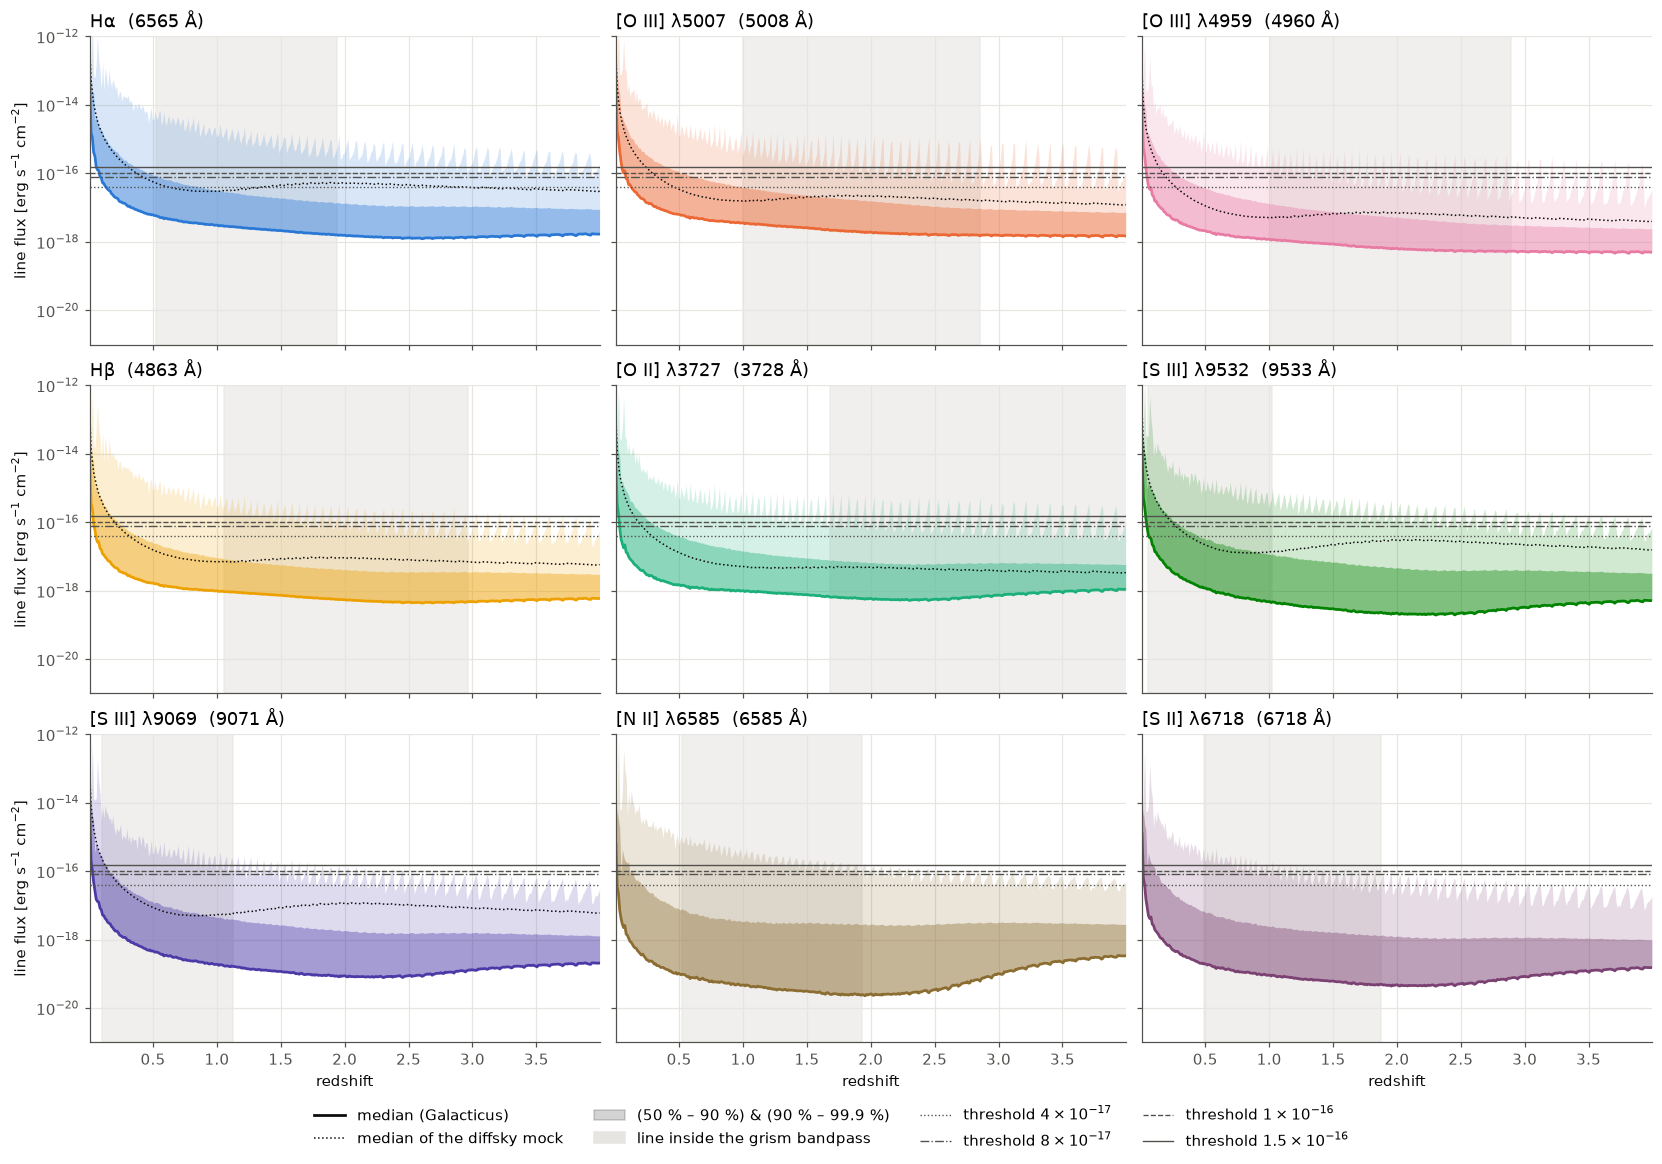

In [3]:
PANELS = ["Ha", "OIII_5007", "OIII_4959", "Hb", "OII_3727", "SIII_9532", "SIII_9069", "NII_6585", "SII_6718"]

fig, axes = plt.subplots(3, 3, figsize=(15, 10.5), sharex=True, sharey=True, constrained_layout=True)
for ax, line in zip(axes.ravel(), PANELS):
    lo, hi = band(line)
    ax.axvspan(max(lo, z[0] - 0.05), min(hi, z[-1] + 0.05), color=plotting.GRID, alpha=0.6, zorder=0)
    col = plotting.feature_color(line)
    ax.fill_between(z, dist.quantile(line, 0.5), dist.quantile(line, 0.9), color=col, alpha=0.5, lw=0)
    ax.fill_between(z, dist.quantile(line, 0.9), dist.quantile(line, 0.999), color=col, alpha=0.18, lw=0)
    ax.plot(z, dist.quantile(line, 0.5), color=col, lw=1.8)
    if line in diffsky.line_names:
        ax.plot(diffsky.z, diffsky.quantile(line, 0.5), color=plotting.TEXT_PRIMARY, lw=1.0, ls=":")
    for value, ls in THRESHOLDS.items():
        ax.axhline(value, color=plotting.TEXT_SECONDARY, lw=0.9, ls=ls)
    ax.set_yscale("log")
    ax.set_ylim(1e-21, 1e-12)
    ax.set_xlim(z[0], z[-1])
    ax.set_title(f"{LABEL(line)}  ({line_set.rest_waves[line_set.bit(line)]:.0f} Å)", loc="left")
for ax in axes[:, 0]:
    ax.set_ylabel("line flux [erg s$^{-1}$ cm$^{-2}$]")
for ax in axes[-1]:
    ax.set_xlabel("redshift")
handles = [Line2D([], [], color=plotting.TEXT_PRIMARY, lw=1.8, label="median (Galacticus)"),
           Line2D([], [], color=plotting.TEXT_PRIMARY, lw=1.0, ls=":", label="median of the diffsky mock"),
           Patch(color=plotting.TEXT_PRIMARY, alpha=0.18, label="(50 % – 90 %) & (90 % – 99.9 %)"),
           Patch(color=plotting.GRID, label="line inside the grism bandpass")]
handles += [Line2D([], [], color=plotting.TEXT_SECONDARY, lw=0.9, ls=ls, label=f"threshold {sci(v)}") for v, ls in THRESHOLDS.items()]
fig.legend(handles=handles, loc="outside lower center", ncol=4, frameon=False)
plt.show()

### All lines in one panel

The same quantiles for the nine lines that matter for the catalog, each drawn **only over the redshift range in
which the line is inside the grism bandpass** (10 000–19 300 Å). The solid line is the median, the shaded bands
run from the median to the 90 % and to the 99.9 % quantile. Where the bands of two lines overlap, both lines
are available to the same galaxies.

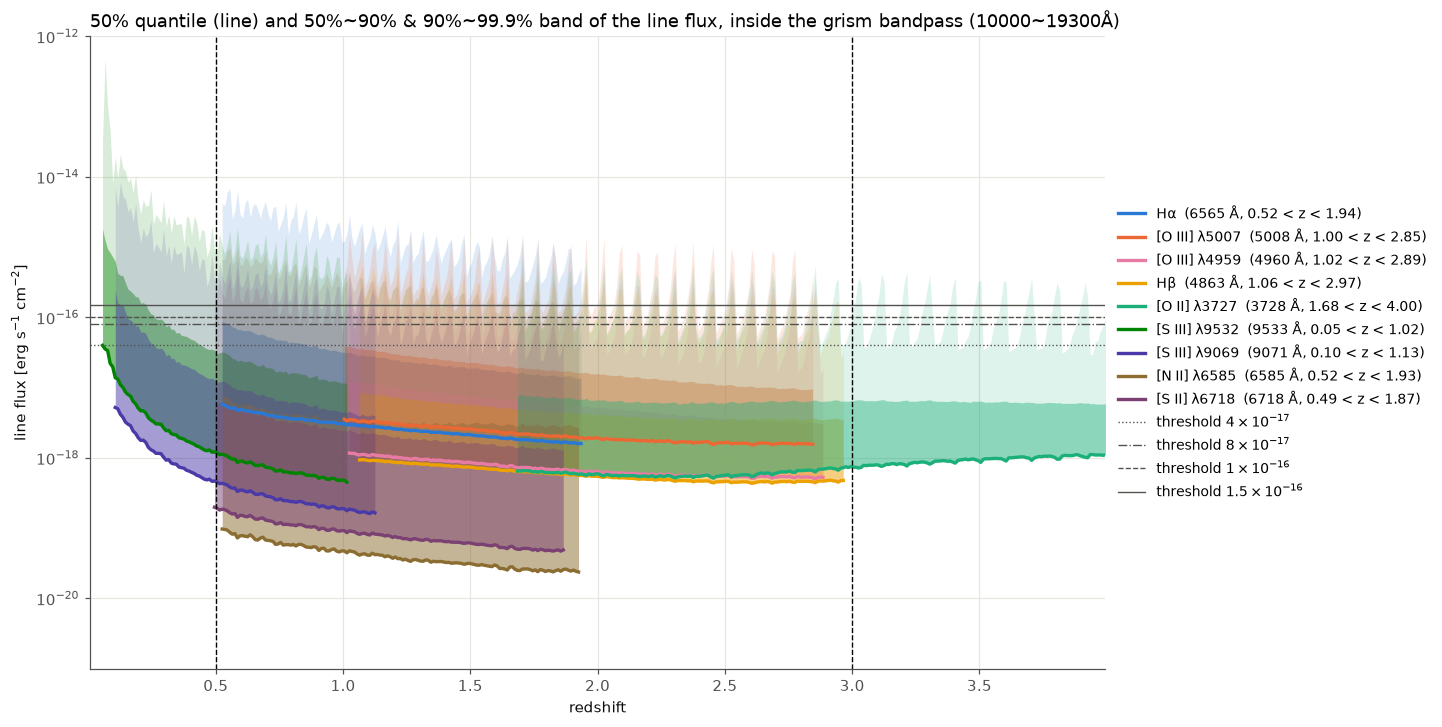

In [4]:
fig, ax = plt.subplots(figsize=(13, 6.5), constrained_layout=True)
for line in PANELS:
    lo, hi = band(line)
    inside = (z > lo) & (z < hi)                                   # redshift bins with the line in the bandpass
    col = plotting.feature_color(line)
    rest = line_set.rest_waves[line_set.bit(line)]
    ax.fill_between(z[inside], dist.quantile(line, 0.5)[inside], dist.quantile(line, 0.9)[inside], color=col, alpha=0.5, lw=0)
    ax.fill_between(z[inside], dist.quantile(line, 0.9)[inside], dist.quantile(line, 0.999)[inside], color=col, alpha=0.15, lw=0)
    ax.plot(z[inside], dist.quantile(line, 0.5)[inside], color=col, lw=2.2,
            label=f"{LABEL(line)}  ({rest:.0f} Å, {max(lo, 0):.2f} < z < {min(hi, z[-1]):.2f})")
for value, ls in THRESHOLDS.items():
    ax.axhline(value, color=plotting.TEXT_SECONDARY, lw=0.9, ls=ls, label=f"threshold {sci(value)}")
ax.axvline(0.5, color="black", lw=0.9, ls="dashed")
ax.axvline(3.0, color="black", lw=0.9, ls="dashed")
ax.set_yscale("log")
ax.set_ylim(1e-21, 1e-12)
ax.set_xlim(z[0], z[-1])
ax.set_xlabel("redshift")
ax.set_ylabel("line flux [erg s$^{-1}$ cm$^{-2}$]")
ax.set_title("50% quantile (line) and 50%~90% & 90%~99.9% band of the line flux, inside the grism bandpass (10000~19300Å)", loc="left")
ax.legend(frameon=False, fontsize=9, loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.show()

## Fraction of galaxies above the thresholds

The fraction of all galaxies at a redshift whose line exceeds each threshold, in bins of 0.05 (solid: Galacticus;
dotted black: the diffsky mock at 10⁻¹⁶). The fraction itself is not comparable between the mocks, because the
Galacticus mock contains many more faint galaxies per volume; the comparable quantity is the number of emitters
per square degree, in the next section.

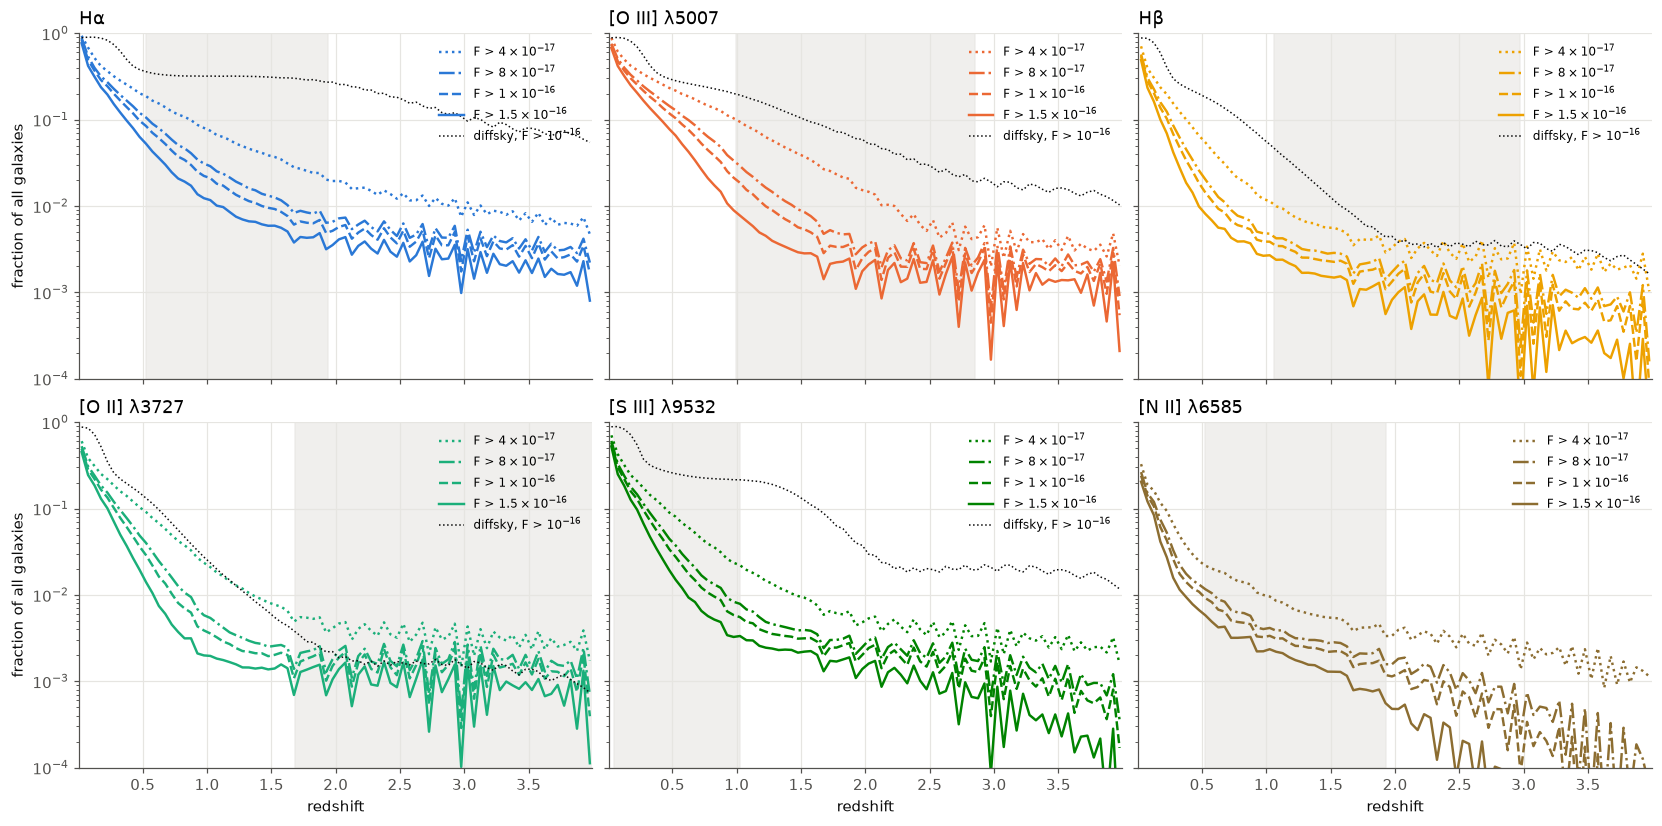

galaxies per redshift bin of 0.05 per deg²: Galacticus [10868, 26652, 34758, 34323, 32534, 26929, 21472], diffsky [1842, 3294, 2909, 2772, 2061, 1415, 815] at z = [0.525, 1.025, 1.525, 2.025, 2.525, 3.025, 3.525]
Hα             median flux [-17.53, -17.82, -17.86] (log10, at z [1.02, 2.02, 3.02]; diffsky [-16.51, -16.29, -16.42]); fraction above 1e-16: [0.021, 0.0057, 0.0045] (diffsky [0.32, 0.256, 0.096])
[O III] λ5007  median flux [-17.46, -17.73, -17.81] (log10, at z [1.02, 2.02, 3.02]; diffsky [-16.8, -16.67, -16.82]); fraction above 1e-16: [0.0186, 0.0029, 0.0031] (diffsky [0.193, 0.052, 0.017])
Hβ             median flux [-18.02, -18.27, -18.32] (log10, at z [1.02, 2.02, 3.02]; diffsky [-17.15, -17.05, -17.17]); fraction above 1e-16: [0.0039, 0.0016, 0.0013] (diffsky [0.052, 0.004, 0.003])


In [5]:
SHOW = ["Ha", "OIII_5007", "Hb", "OII_3727", "SIII_9532", "NII_6585"]
coarse, diffsky_coarse = dist.rebin(5), diffsky.rebin(5)                       # bins of 0.05
fig, axes = plt.subplots(2, 3, figsize=(15, 7.4), sharex=True, sharey=True, constrained_layout=True)
for ax, line in zip(axes.ravel(), SHOW):
    lo, hi = band(line)
    ax.axvspan(max(lo, z[0] - 0.05), min(hi, z[-1] + 0.05), color=plotting.GRID, alpha=0.6, zorder=0)
    for value, ls in THRESHOLDS.items():
        ax.plot(coarse.z, coarse.fraction_above(line, value), color=plotting.feature_color(line), ls=ls, lw=1.6, label=f"F > {sci(value)}")
    if line in diffsky.line_names:
        ax.plot(diffsky_coarse.z, diffsky_coarse.fraction_above(line, 1e-16), color=plotting.TEXT_PRIMARY, lw=1.0, ls=":", label=r"diffsky, F > $10^{-16}$")
    ax.set_yscale("log")
    ax.set_ylim(1e-4, 1)
    ax.set_xlim(z[0], z[-1])
    ax.set_title(LABEL(line), loc="left")
    ax.legend(frameon=False, fontsize=8, loc="upper right")
for ax in axes[:, 0]:
    ax.set_ylabel("fraction of all galaxies")
for ax in axes[-1]:
    ax.set_xlabel("redshift")
plt.show()

at = np.searchsorted(coarse.z, [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5])              # bins at these redshifts
dz = coarse.z_edges[1] - coarse.z_edges[0]
print(f"galaxies per redshift bin of {dz:.2f} per deg²: Galacticus {np.round(coarse.n_gal[at] / mock.area_deg2).astype(int).tolist()}, "
      f"diffsky {np.round(diffsky_coarse.n_gal[at] / 2062.65).astype(int).tolist()} at z = {np.round(coarse.z[at], 3).tolist()}")
for line in ("Ha", "OIII_5007", "Hb"):
    print(f"{LABEL(line):<14s} median flux {np.log10(coarse.quantile(line, 0.5))[at[1::2]].round(2).tolist()} (log10, at z {np.round(coarse.z[at[1::2]], 2).tolist()}; "
          f"diffsky {np.log10(diffsky_coarse.quantile(line, 0.5))[at[1::2]].round(2).tolist()}); fraction above 1e-16: "
          f"{coarse.fraction_above(line, 1e-16)[at[1::2]].round(4).tolist()} (diffsky {diffsky_coarse.fraction_above(line, 1e-16)[at[1::2]].round(3).tolist()})")

## Emitters per square degree

The number of galaxies per square degree and per unit redshift whose line exceeds the threshold, inside the
bandpass: the dN/dz of notebook 01, here for the two mocks side by side (Galacticus solid, diffsky dashed) and
the Wang et al. (2022) forecast at 10⁻¹⁶ (points, Hα and [O III] λ5007 with $A_V$ = 1.65 and 1.92, the
reference of the package). The bins of 0.01 are summed to 0.1 to match the forecast.

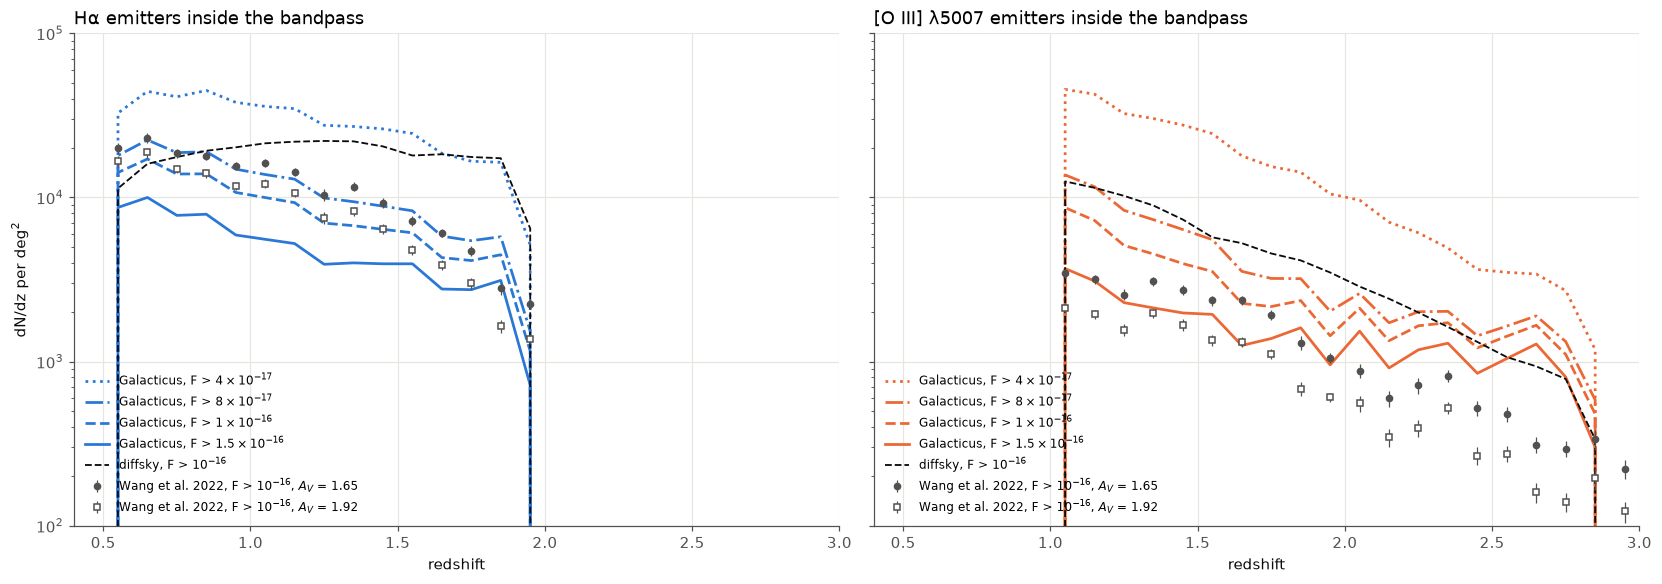

Hα             above 1e-16, 0.5 < z < 2.0: 12,939 per deg² (Galacticus), 26,998 (diffsky), 17,990 (Wang 2022, A_V 1.65); Galacticus / Wang = [0.71, 0.74, 0.75, 0.78, 0.69, 0.61, 0.65, 0.67, 0.58, 0.69, 0.85, 0.71, 0.88, 1.6, 0.52] at z = [0.55, 0.65, 0.75, 0.85, 0.95, 1.05, 1.15, 1.25, 1.35, 1.45, 1.55, 1.65, 1.75, 1.85, 1.95]
[O III] λ5007  above 1e-16, 1.0 < z < 3.0: 5,393 per deg² (Galacticus), 8,693 (diffsky), 2,916 (Wang 2022, A_V 1.65); Galacticus / Wang = [2.52, 2.28, 1.99, 1.46, 1.45, 1.5, 0.96, 1.12, 1.8, 1.36, 2.42, 2.24, 2.31, 2.1, 2.33, 2.99, 5.33, 3.75, 1.42, 0.0] at z = [1.05, 1.15, 1.25, 1.35, 1.45, 1.55, 1.65, 1.75, 1.85, 1.95, 2.05, 2.15, 2.25, 2.35, 2.45, 2.55, 2.65, 2.75, 2.85, 2.95]


In [6]:
from romanmock.reference_dndz import wang2022_bins, wang2022_errors

def dndz_per_deg2(d, line, flux, area, step=10):
    '''dN/dz per deg² of the emitters inside the bandpass, in redshift bins of `step` x 0.01.'''
    n = np.where((d.z > band(line)[0]) & (d.z < band(line)[1]), d.number_above(line, flux), 0.0)   # per bin of 0.01
    n = n[: n.size // step * step].reshape(-1, step).sum(axis=1)
    edges = d.z_edges[: n.size * step + 1 : step]
    return 0.5 * (edges[1:] + edges[:-1]), n / area / (edges[1:] - edges[:-1])

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), sharey=True, constrained_layout=True)
for ax, line in zip(axes, ("Ha", "OIII_5007")):
    col = plotting.feature_color(line)
    for value, ls in THRESHOLDS.items():
        zc, g = dndz_per_deg2(dist, line, value, mock.area_deg2)
        ax.plot(zc, g, color=col, ls=ls, lw=1.8, label=f"Galacticus, F > {sci(value)}")
    zc, g = dndz_per_deg2(diffsky, line, 1e-16, 2062.65)
    ax.plot(zc, g, color=plotting.TEXT_PRIMARY, ls="--", lw=1.2, label=r"diffsky, F > $10^{-16}$")
    for av, marker in ((1.65, "o"), (1.92, "s")):
        edges, ref = wang2022_bins(line, 1e-16, av)
        ax.errorbar(0.5 * (edges[1:] + edges[:-1]), ref, yerr=wang2022_errors(line, 1e-16, av), fmt=marker, ms=4, color=plotting.TEXT_SECONDARY,
                    mfc="white" if av == 1.92 else plotting.TEXT_SECONDARY, lw=0.8, label=rf"Wang et al. 2022, F > $10^{{-16}}$, $A_V$ = {av}")
    ax.set_yscale("log")
    ax.set_ylim(1e2, 1e5)
    ax.set_xlim(0.4, 3.0)
    ax.set_xlabel("redshift")
    ax.set_title(f"{LABEL(line)} emitters inside the bandpass", loc="left")
    ax.legend(frameon=False, fontsize=8, loc="lower left")
axes[0].set_ylabel("dN/dz per deg$^2$")
plt.show()

for line in ("Ha", "OIII_5007"):
    zc, g = dndz_per_deg2(dist, line, 1e-16, mock.area_deg2)
    _, d = dndz_per_deg2(diffsky, line, 1e-16, 2062.65)
    edges, ref = wang2022_bins(line, 1e-16, 1.65)
    sel = (zc > edges[0]) & (zc < edges[-1])
    r = np.interp(zc[sel], 0.5 * (edges[1:] + edges[:-1]), ref)
    print(f"{LABEL(line):<14s} above 1e-16, {edges[0]:.1f} < z < {edges[-1]:.1f}: {g[sel].sum() * 0.1:,.0f} per deg² (Galacticus), "
          f"{d[sel].sum() * 0.1:,.0f} (diffsky), {ref.sum() * 0.1:,.0f} (Wang 2022, A_V 1.65); Galacticus / Wang = "
          f"{np.round(g[sel] / r, 2).tolist()} at z = {np.round(zc[sel], 2).tolist()}")

## Galacticus against diffsky and the forecast

**Depth.** The Galacticus mock has 35 000 galaxies per deg² per redshift bin of 0.05 at z = 1.5–2.5 against 2 900
in the diffsky mock, and its median Hα flux is 3×10⁻¹⁸ instead of 3–5×10⁻¹⁷: it resolves galaxies ten times
less massive. Above 10⁻¹⁶ only 2 % of its galaxies have Hα at z = 1 (0.6 % at z = 2), against 32 % (26 %) in
diffsky. The fractions therefore say nothing about the two mocks' emitter populations; the counts per square
degree do.

**Hα counts.** Inside the bandpass, above 10⁻¹⁶, the Galacticus mock has 12 900 Hα emitters per deg² at
0.5 < z < 2.0, against 27 000 in diffsky and 18 000 in the Wang et al. (2022) forecast with $A_V$ = 1.65. Its
dN/dz is 0.7 of the forecast at every redshift (0.6–0.9), and runs along the forecast's $A_V$ = 1.92 variant;
the diffsky mock is 1.5 times the forecast and falls more slowly with redshift. The Galacticus Hα calibration
(Sobral et al. luminosity functions at z = 0.4–2.2) therefore sits below the Roman reference model. Note that
in the Galacticus mock the [N II] λ6585 line carries a median 0.24 of the Hα flux (10–90 %: 0–0.46): a grism
that does not separate the two would measure Hα + [N II] fluxes 1.2–1.5 times those used here, which the
diffsky mock cannot show because it has no [N II].

**[O III] counts.** Above 10⁻¹⁶ at 1.0 < z < 3.0 the Galacticus mock has 5 400 [O III] λ5007 emitters per deg²,
diffsky 8 700 and the forecast 2 900: Galacticus is 1–2.5 times the forecast below z = 2.0 and 2–5 times
above, where the forecast falls faster than either mock. Both mocks, with different line models and galaxy
populations, exceed the forecast's [O III] counts at z > 2.

**Where the difference between the mocks comes from.** The 99.9 % quantiles of the Galacticus mock are above
those of diffsky for every line (its brightest galaxies are brighter), while its median is far below: the
Galacticus population spans a wider range in luminosity. The counts above the thresholds depend on the bright
tail only, and there the two mocks differ by a factor of 2 in Hα and 1.6 in [O III], in opposite directions
relative to the forecast.

## The lines of a selected galaxy

The single-line fraction depends on the *joint* distribution: given that a galaxy is selected by one line, how
often does another line exceed the line-detection threshold? The histograms above are marginal, so this part
reads the fluxes of the galaxies at 0.5 < z < 2.9 directly from the mock (`mock.read_fluxes`, 22 M galaxies,
3 minutes with four workers on a login node). Galaxies selected by Hα (0.52 < z < 1.94) and by [O III] λ5007
where Hα is outside the bandpass (1.94 < z < 2.85).

21,876,858 galaxies at 0.5 < z < 2.9


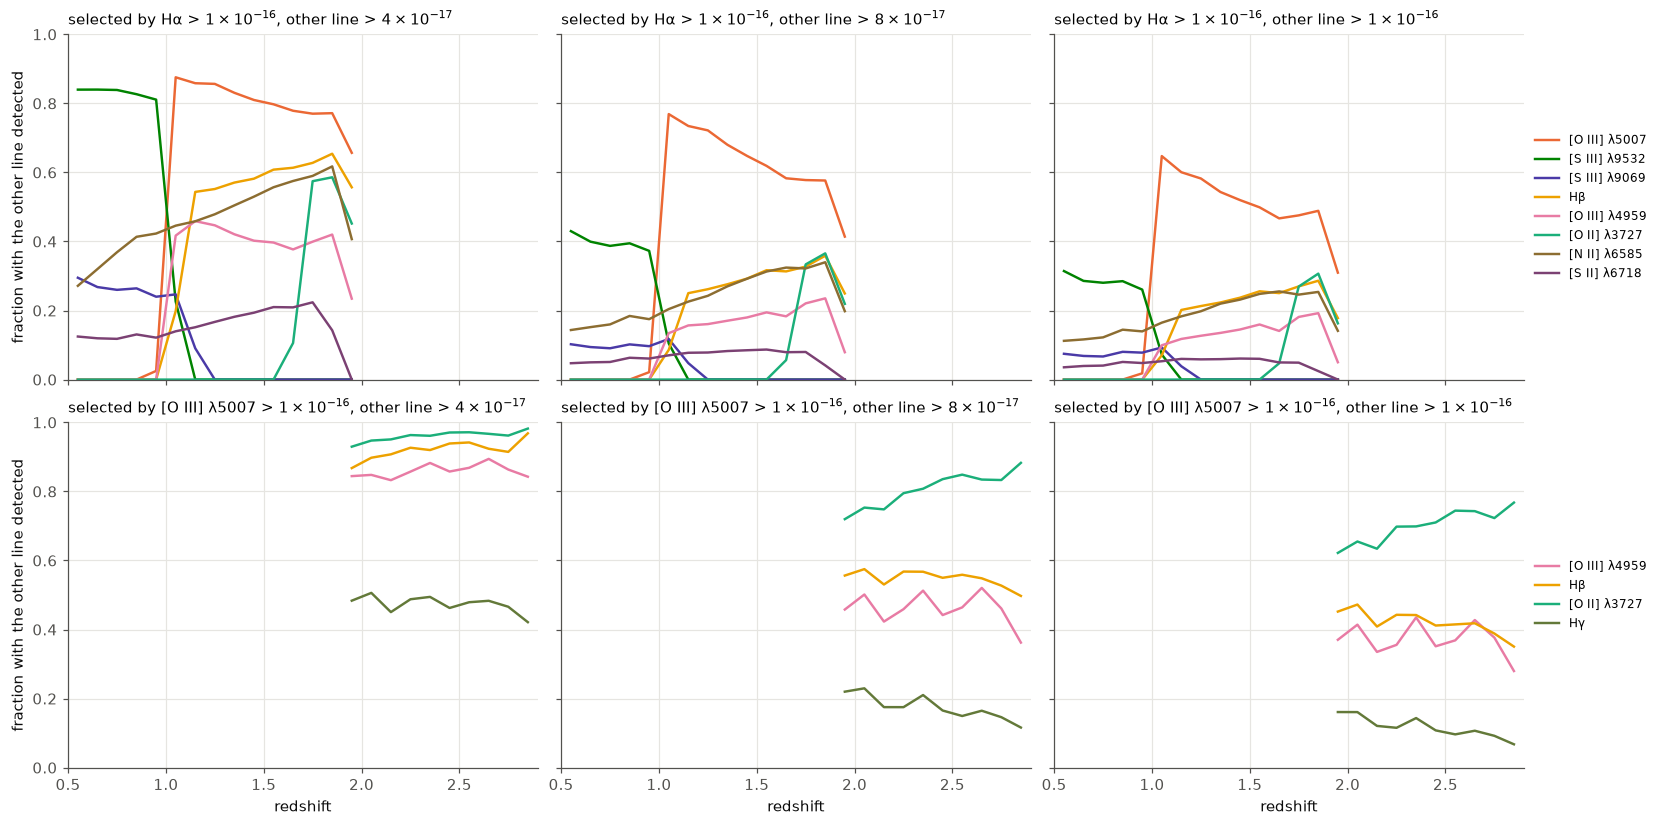

Hα             selected, other line > 4e-17: single-line fraction at z [0.65, 1.15, 1.65, 1.85] = [0.16, 0.05, 0.07, 0.08]


Hα             selected, other line > 8e-17: single-line fraction at z [0.65, 1.15, 1.65, 1.85] = [0.6, 0.18, 0.29, 0.3]


Hα             selected, other line > 1e-16: single-line fraction at z [0.65, 1.15, 1.65, 1.85] = [0.71, 0.32, 0.43, 0.42]
[O III] λ5007  selected, other line > 4e-17: single-line fraction at z [2.05, 2.45, 2.85] = [0.02, 0.01, 0.01]


[O III] λ5007  selected, other line > 8e-17: single-line fraction at z [2.05, 2.45, 2.85] = [0.22, 0.15, 0.1]
[O III] λ5007  selected, other line > 1e-16: single-line fraction at z [2.05, 2.45, 2.85] = [0.31, 0.27, 0.22]


line ratios of the selected galaxies (10 %, 50 %, 90 %): {'NII_6585': [0.0, 0.239, 0.461], 'SIII_9532': [0.012, 0.452, 0.583], 'OIII_5007': [0.049, 0.646, 1.15], 'Hb': [0.189, 0.245, 0.33], 'OIII_4959/OIII_5007': [0.329, 0.333, 0.335], 'Hb/OIII_5007': [0.192, 0.309, 0.493]}


In [7]:
F_SEL = 1.0e-16
lines_all = ["Ha", "OIII_5007", "OIII_4959", "Hb", "OII_3727", "SIII_9532", "SIII_9069", "NII_6585", "SII_6718", "Hg"]
sample = mock.read_fluxes(line_set.subset(lines_all), columns=["redshift_rsd"], z_range=(0.5, 2.9), z_column="redshift_rsd", n_workers=4)
zs = sample["redshift_rsd"]
flux = {l: sample[f"{l}_flux"] for l in lines_all}
edges = np.arange(0.5, 2.9 + 1e-9, 0.1)
zc = 0.5 * (edges[1:] + edges[:-1])
print(f"{zs.size:,} galaxies at 0.5 < z < 2.9")

def in_band(line, redshift):
    lo, hi = band(line)
    return (redshift > lo) & (redshift < hi)

def fraction_with(selected, other, limit):
    '''Per redshift bin: fraction of the selected galaxies whose line `other` is inside the bandpass and above `limit`.'''
    has = selected & in_band(other, zs) & (flux[other] > limit)
    n_sel, n_has = np.histogram(zs[selected], bins=edges)[0], np.histogram(zs[has], bins=edges)[0]
    with np.errstate(invalid="ignore"):
        return np.where(n_sel > 200, n_has / n_sel, np.nan)

SELECTIONS = {"Ha": ["OIII_5007", "SIII_9532", "SIII_9069", "Hb", "OIII_4959", "OII_3727", "NII_6585", "SII_6718"],
              "OIII_5007": ["OIII_4959", "Hb", "OII_3727", "Hg"]}
F_LINE = [4e-17, 8e-17, 1e-16]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.4), sharex=True, sharey=True, constrained_layout=True)
for row, (sel_line, others) in zip(axes, SELECTIONS.items()):
    selected = in_band(sel_line, zs) & (flux[sel_line] > F_SEL)
    if sel_line == "OIII_5007":
        selected &= ~in_band("Ha", zs)
    for ax, f_line in zip(row, F_LINE):
        for other in others:
            ax.plot(zc, fraction_with(selected, other, f_line), color=plotting.feature_color(other), lw=1.6, label=LABEL(other))
        ax.set_ylim(0, 1)
        ax.set_xlim(edges[0], edges[-1])
        ax.set_title(rf"selected by {LABEL(sel_line)} > {sci(F_SEL)}, other line > {sci(f_line)}", loc="left", fontsize=10)
    row[0].set_ylabel("fraction with the other line detected")
    row[-1].legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1.0, 0.5))
for ax in axes[-1]:
    ax.set_xlabel("redshift")
plt.show()

for sel_line, others in SELECTIONS.items():
    selected = in_band(sel_line, zs) & (flux[sel_line] > F_SEL)
    if sel_line == "OIII_5007":
        selected &= ~in_band("Ha", zs)
    for f_line in F_LINE:
        any_other = np.zeros(zs.size, dtype=bool)
        for other in others:
            any_other |= in_band(other, zs) & (flux[other] > f_line)
        n_sel, n_any = np.histogram(zs[selected], bins=edges)[0], np.histogram(zs[selected & any_other], bins=edges)[0]
        with np.errstate(invalid="ignore"):
            single = np.where(n_sel > 200, 1 - n_any / n_sel, np.nan)
        picks = [1, 6, 11, 13] if sel_line == "Ha" else [15, 19, 23]
        print(f"{LABEL(sel_line):<14s} selected, other line > {f_line:.0e}: single-line fraction at z {np.round(zc[picks], 2).tolist()} = "
              f"{np.round(single[picks], 2).tolist()}")

ratios = {}
for other in ("NII_6585", "SIII_9532", "OIII_5007", "Hb"):
    sel = in_band("Ha", zs) & (flux["Ha"] > F_SEL) & in_band(other, zs)
    ratios[other] = np.percentile(flux[other][sel] / flux["Ha"][sel], [10, 50, 90]).round(3).tolist()
sel = in_band("OIII_5007", zs) & (flux["OIII_5007"] > F_SEL)
for other in ("OIII_4959", "Hb"):
    ratios[f"{other}/OIII_5007"] = np.percentile(flux[other][sel] / flux["OIII_5007"][sel], [10, 50, 90]).round(3).tolist()
print("line ratios of the selected galaxies (10 %, 50 %, 90 %):", ratios)
del sample, flux

**The companions of an Hα emitter.** In the Galacticus mock the line ratios scatter where in diffsky they are
fixed: for the Hα emitters above 10⁻¹⁶, [O III] λ5007/Hα has a median of 0.65 (10–90 %: 0.05–1.15), [S III]
λ9532/Hα 0.45 (0.01–0.58), Hβ/Hα 0.245 (0.19–0.33), [N II] λ6585/Hα 0.24 (0–0.46). With a line-detection
threshold of 4×10⁻¹⁷, [S III] λ9532 accompanies 84 % of the Hα emitters below z = 0.95, then leaves the bandpass;
above z = 1.0 [O III] λ5007 is detected in 80–88 % of them, falling to 65 % at z = 1.9, Hβ and [N II] λ6585 in
45–65 %, [O III] λ4959 in 40 % and, beyond z = 1.7, [O II] λ3727 in 60 %. The Hα single-line fraction is 16 % at
z = 0.65 (2 % in diffsky, where [S III] is present in 98 %), 5–8 % at z > 1 (6–10 % in diffsky). With 8×10⁻¹⁷
it is 60 % at z = 0.65 and 18–30 % above z = 1 (diffsky: 22 %, 33–62 %); with 10⁻¹⁶ it is 71 % and 32–43 %
(diffsky: 29 %, 48–76 %). Above z = 1 the Galacticus Hα emitters are *less* often single-line than the diffsky
ones at the higher thresholds, because their [O III]/Hα ratio is higher (0.65 against 0.44) and because [N II],
[O II] and Hβ add companions that diffsky lacks or has fainter.

**The companions of an [O III] λ5007 emitter beyond z = 1.94.** [O III] λ4959/λ5007 is fixed at 0.333 (the
atomic ratio; 0.329 in diffsky), Hβ/λ5007 has a median of 0.31 (0.19–0.49; fixed at 0.45 in diffsky), and the
[O II] λ3727 blend is strong: with a threshold of 4×10⁻¹⁷ it is detected in 93–97 % of the [O III] emitters, Hβ
in 90–97 %, λ4959 in 85–90 %, Hγ in 45–50 %, so almost none of them is single-line (1–2 %). With 8×10⁻¹⁷ [O II]
is still present in 72–88 %, Hβ in 50–57 % and λ4959 in 45–52 %: the single-line fraction is 10–22 %, and with
10⁻¹⁶ it is 22–31 % ([O II] in 62–77 %). In diffsky, which has no bright [O II] and fixed ratios, the same
selections give 72–84 % and 82–92 %: the [O III] single-line fraction, and with it the confusion between
[O III] and Hα, depends strongly on the line model of the mock.